In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list
import missingno as msno

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

Once your Google Drive is mounted, please provide the full path to your data file (e.g., `/content/drive/MyDrive/my_folder/my_data.csv`). I will then generate the code to load it.

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [ ]:
df_raw = pd.read_csv('/content/drive/MyDrive/AUS_meteo/AUS_weather_trend_grouped.csv')

In [ ]:
df =df_raw.copy()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140787 entries, 0 to 140786
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Date                 140787 non-null  object 
 1   Location             140787 non-null  object 
 2   MinTemp              140319 non-null  float64
 3   MaxTemp              140480 non-null  float64
 4   Rainfall             140787 non-null  float64
 5   Evaporation          81093 non-null   float64
 6   Sunshine             73982 non-null   float64
 7   WindGustDir          131624 non-null  object 
 8   WindGustSpeed        131682 non-null  float64
 9   WindDir9am           131127 non-null  object 
 10  WindDir3pm           137117 non-null  object 
 11  WindSpeed9am         139732 non-null  float64
 12  WindSpeed3pm         138256 non-null  float64
 13  Humidity9am          139270 non-null  float64
 14  Humidity3pm          137286 non-null  float64
 15  Pressure9am      

In [ ]:
cols_to_check = ['MinTemp', 'MaxTemp', 'Rainfall', 'Humidity9am','Temp9am','RainToday']

def calculate_loss(group):
    initial = len(group)
    after_drop = len(group.dropna(subset=cols_to_check))
    lost = initial - after_drop
    pct = (lost / initial) * 100
    return pd.Series({'Initial Rows': initial, 'Remaining Rows': after_drop, 'Rows Lost': lost, 'Loss %': pct})

loss_by_group = df.groupby('weather_trend_group').apply(calculate_loss)
display(loss_by_group.style.format({'Loss %': '{:.2f}%'}))

print(f"\nOverall average loss across all groups: {((len(df) - len(df.dropna(subset=cols_to_check))) / len(df)) * 100:.2f}%")

/tmp/ipykernel_1230/4202030488.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  loss_by_group = df.groupby('weather_trend_group').apply(calculate_loss)


,Initial Rows,Remaining Rows,Rows Lost,Loss %
weather_trend_group,,,,
AI,57903.000000,56787.000000,1116.000000,1.93%
CS,38102.000000,37548.000000,554.000000,1.45%
TP,10728.000000,10632.000000,96.000000,0.89%
TS,34054.000000,33853.000000,201.000000,0.59%



Overall average loss across all groups: 1.40%


In [ ]:
df.dropna(subset=cols_to_check, inplace=True)
print(f"Shape of DataFrame after dropping nulls: {df.shape}")

Shape of DataFrame after dropping nulls: (138820, 25)


In [ ]:
sunshine_null_counts = df['Sunshine'].isnull().groupby(df['weather_trend_group']).sum().reset_index()
sunshine_null_counts.columns = ['weather_trend_group', 'Null_Count_Sunshine']
display(sunshine_null_counts)

,weather_trend_group,Null_Count_Sunshine
0,AI,29386
1,CS,22791
2,TP,2270
3,TS,10871


In [ ]:
df_AI = df[df['weather_trend_group']=='AI']
df_AI.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,Month,weather_trend_group
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,1007.7,1007.1,8.0,NaN,16.9,21.8,False,False,12,AI
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,1010.6,1007.8,NaN,NaN,17.2,24.3,False,False,12,AI
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,1007.6,1008.7,NaN,2.0,21.0,23.2,False,False,12,AI
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,1017.6,1012.8,NaN,NaN,18.1,26.5,False,False,12,AI
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,1010.8,1006.0,7.0,8.0,17.8,29.7,False,False,12,AI


In [ ]:
df_AI.info()

<class 'pandas.core.frame.DataFrame'>
Index: 56787 entries, 0 to 131522
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Date                 56787 non-null  object 
 1   Location             56787 non-null  object 
 2   MinTemp              56787 non-null  float64
 3   MaxTemp              56787 non-null  float64
 4   Rainfall             56787 non-null  float64
 5   Evaporation          29382 non-null  float64
 6   Sunshine             27401 non-null  float64
 7   WindGustDir          53038 non-null  object 
 8   WindGustSpeed        53057 non-null  float64
 9   WindDir9am           52546 non-null  object 
 10  WindDir3pm           55376 non-null  object 
 11  WindSpeed9am         56493 non-null  float64
 12  WindSpeed3pm         55768 non-null  float64
 13  Humidity9am          56787 non-null  float64
 14  Humidity3pm          55996 non-null  float64
 15  Pressure9am          52714 non-null  flo

In [ ]:
df_AI_Sun = df_AI[['Date','Location','MinTemp', 'MaxTemp', 'Rainfall', 'Humidity9am','Temp9am','RainToday','Month','Sunshine']]
df_AI_Sun.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Humidity9am,Temp9am,RainToday,Month,Sunshine
0,2008-12-01,Albury,13.4,22.9,0.6,71.0,16.9,False,12,NaN
1,2008-12-02,Albury,7.4,25.1,0.0,44.0,17.2,False,12,NaN
2,2008-12-03,Albury,12.9,25.7,0.0,38.0,21.0,False,12,NaN
3,2008-12-04,Albury,9.2,28.0,0.0,45.0,18.1,False,12,NaN
4,2008-12-05,Albury,17.5,32.3,1.0,82.0,17.8,False,12,NaN


In [ ]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# Define the columns to use for MICE
# Including 'RainToday' as a numeric (0/1) for the imputer
cols_for_mice = ['MinTemp', 'MaxTemp', 'Rainfall', 'Humidity9am', 'Temp9am', 'Month', 'Sunshine']
df_mice = df_AI_Sun[cols_for_mice].copy()
df_mice['RainToday'] = df_AI_Sun['RainToday'].astype(int)

# Initialize and fit IterativeImputer
imputer = IterativeImputer(random_state=42, max_iter=10)
imputed_data = imputer.fit_transform(df_mice)

# Create a temporary dataframe with imputed values
df_imputed = pd.DataFrame(imputed_data, columns=df_mice.columns, index=df_AI_Sun.index)

# Update the original df_AI_Sun 'Sunshine' column
df_AI_Sun = df_AI_Sun.copy()
df_AI_Sun['Sunshine'] = df_imputed['Sunshine']

print(f"Missing values in Sunshine after MICE: {df_AI_Sun['Sunshine'].isnull().sum()}")
display(df_AI_Sun.head())

Missing values in Sunshine after MICE: 0


,Date,Location,MinTemp,MaxTemp,Rainfall,Humidity9am,Temp9am,RainToday,Month,Sunshine
0,2008-12-01,Albury,13.4,22.9,0.6,71.0,16.9,False,12,6.783743
1,2008-12-02,Albury,7.4,25.1,0.0,44.0,17.2,False,12,10.551468
2,2008-12-03,Albury,12.9,25.7,0.0,38.0,21.0,False,12,9.082359
3,2008-12-04,Albury,9.2,28.0,0.0,45.0,18.1,False,12,11.307149
4,2008-12-05,Albury,17.5,32.3,1.0,82.0,17.8,False,12,9.661134


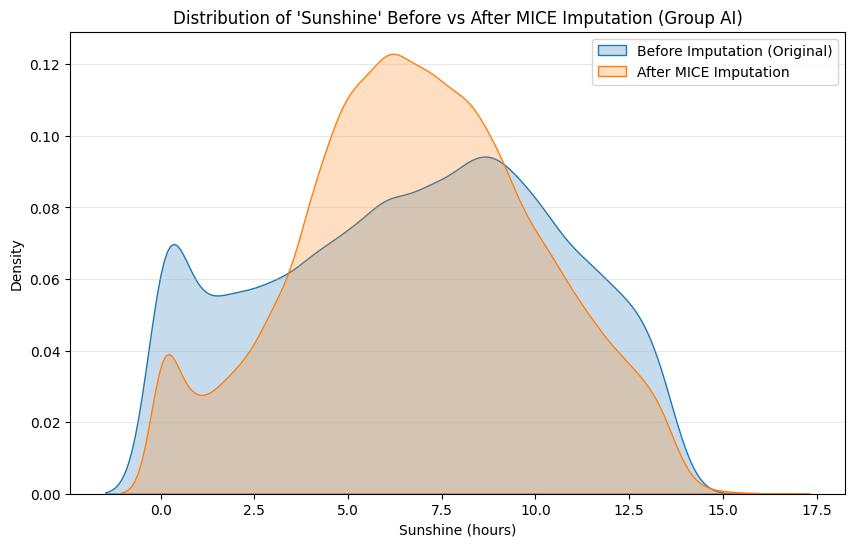

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Distribution before imputation (dropping NaNs for the plot)
sns.kdeplot(df_mice['Sunshine'].dropna(), label='Before Imputation (Original)', fill=True)

# Distribution after imputation
sns.kdeplot(df_AI_Sun['Sunshine'], label='After MICE Imputation', fill=True)

plt.title("Distribution of 'Sunshine' Before vs After MICE Imputation (Group AI)")
plt.xlabel('Sunshine (hours)')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 1. Filter rows where Sunshine is NOT NULL to create a ground truth dataset
df_eval = df_AI[cols_for_mice].copy()
df_eval['RainToday'] = df_AI['RainToday'].astype(int)
df_eval_clean = df_eval.dropna(subset=['Sunshine'])

# 2. Split into training and testing sets
train_idx, test_idx = train_test_split(df_eval_clean.index, test_size=0.2, random_state=42)

# 3. Create a version of the test set with Sunshine masked (NaN)
df_eval_masked = df_eval_clean.copy()
df_eval_masked.loc[test_idx, 'Sunshine'] = np.nan

# 4. Fit the imputer on the training data and transform the masked data
eval_imputer = IterativeImputer(random_state=42, max_iter=10)
eval_imputed_data = eval_imputer.fit_transform(df_eval_masked)
eval_df_result = pd.DataFrame(eval_imputed_data, columns=df_eval.columns, index=df_eval_masked.index)

# 5. Calculate Metrics
y_true = df_eval_clean.loc[test_idx, 'Sunshine']
y_pred = eval_df_result.loc[test_idx, 'Sunshine']

mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_true, y_pred)

print(f"Evaluation Results for MICE Imputation:")
print(f"RMSE: {rmse:.4f} hours")
print(f"R² Score: {r2:.4f}")

Evaluation Results for MICE Imputation:
RMSE: 2.9811 hours
R² Score: 0.3778


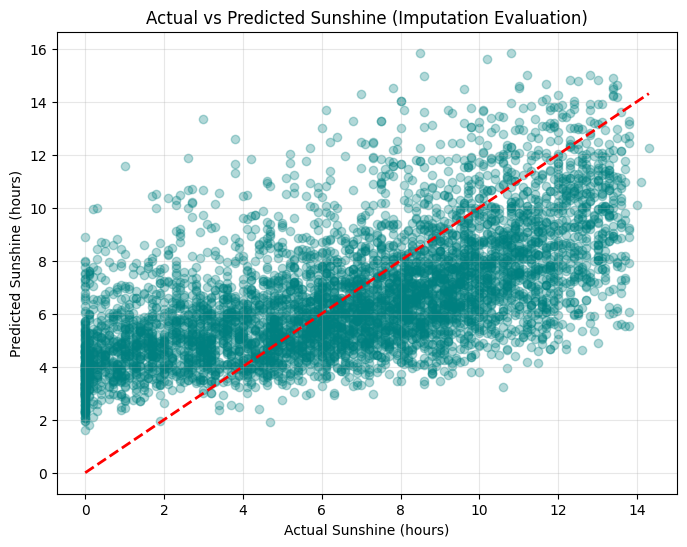

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_true, y_pred, alpha=0.3, color='teal')
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], '--r', linewidth=2)
plt.title('Actual vs Predicted Sunshine (Imputation Evaluation)')
plt.xlabel('Actual Sunshine (hours)')
plt.ylabel('Predicted Sunshine (hours)')
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
from sklearn.impute import SimpleImputer

# 1. Simple Mean Imputation
mean_imputer = SimpleImputer(strategy='mean')
# Fit on training data (where Sunshine is not NaN)
y_train_eval = df_eval_clean.loc[train_idx, 'Sunshine'].values.reshape(-1, 1)
mean_imputer.fit(y_train_eval)

# Predict (impute) for the test set
y_pred_mean = np.full(shape=y_true.shape, fill_value=mean_imputer.statistics_[0])

# 2. Simple Median Imputation
median_imputer = SimpleImputer(strategy='median')
median_imputer.fit(y_train_eval)
y_pred_median = np.full(shape=y_true.shape, fill_value=median_imputer.statistics_[0])

# 3. Compile Comparison
results = {
    'Method': ['MICE', 'Mean Imputation', 'Median Imputation'],
    'RMSE': [
        np.sqrt(mean_squared_error(y_true, y_pred)),
        np.sqrt(mean_squared_error(y_true, y_pred_mean)),
        np.sqrt(mean_squared_error(y_true, y_pred_median))
    ],
    'R2 Score': [
        r2_score(y_true, y_pred),
        r2_score(y_true, y_pred_mean),
        r2_score(y_true, y_pred_median)
    ]
}

comparison_df = pd.DataFrame(results)
display(comparison_df.style.highlight_min(subset=['RMSE'], color='lightgreen').highlight_max(subset=['R2 Score'], color='lightgreen'))

,Method,RMSE,R2 Score
0,MICE,2.981106,0.377768
1,Mean Imputation,3.779213,-0.000001
2,Median Imputation,3.791758,-0.006651


In [ ]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# Define groups and columns
groups_to_impute = ['CS', 'TP', 'TS']
cols_for_mice = ['MinTemp', 'MaxTemp', 'Rainfall', 'Humidity9am', 'Temp9am', 'Month', 'Sunshine']

for group_name in groups_to_impute:
    print(f"Processing group: {group_name}...")

    # 1. Filter the group
    mask = df['weather_trend_group'] == group_name
    df_group = df[mask].copy()

    # 2. Prepare data for MICE (convert RainToday to int if needed, though not in cols_for_mice here)
    # We use the same columns as the AI test
    data_subset = df_group[cols_for_mice].copy()

    # 3. Initialize and fit MICE
    imputer = IterativeImputer(random_state=42, max_iter=10)
    imputed_values = imputer.fit_transform(data_subset)

    # 4. Create temp DataFrame to align indices
    df_temp = pd.DataFrame(imputed_values, columns=cols_for_mice, index=df_group.index)

    # 5. Update the 'Sunshine' column in the main DataFrame 'df'
    df.loc[mask, 'Sunshine'] = df_temp['Sunshine']

print("\nImputation complete for all groups.")

Processing group: CS...
Processing group: TP...
Processing group: TS...

Imputation complete for all groups.


In [ ]:
# 1. Apply imputation to the 'AI' group in the main dataframe 'df'
mask_ai = df['weather_trend_group'] == 'AI'
data_ai = df[mask_ai][cols_for_mice].copy()

imputer_ai = IterativeImputer(random_state=42, max_iter=10)
imputed_ai = imputer_ai.fit_transform(data_ai)

# Update main df
df_temp_ai = pd.DataFrame(imputed_ai, columns=cols_for_mice, index=df[mask_ai].index)
df.loc[mask_ai, 'Sunshine'] = df_temp_ai['Sunshine']

# 2. Final verification across all groups
sunshine_nulls_final = df['Sunshine'].isnull().groupby(df['weather_trend_group']).sum()
print("Remaining missing values in 'Sunshine' by group:")
print(sunshine_nulls_final)
print(f"\nTotal missing values in Sunshine: {df['Sunshine'].isnull().sum()}")

Remaining missing values in 'Sunshine' by group:
weather_trend_group
AI    0
CS    0
TP    0
TS    0
Name: Sunshine, dtype: int64

Total missing values in Sunshine: 0


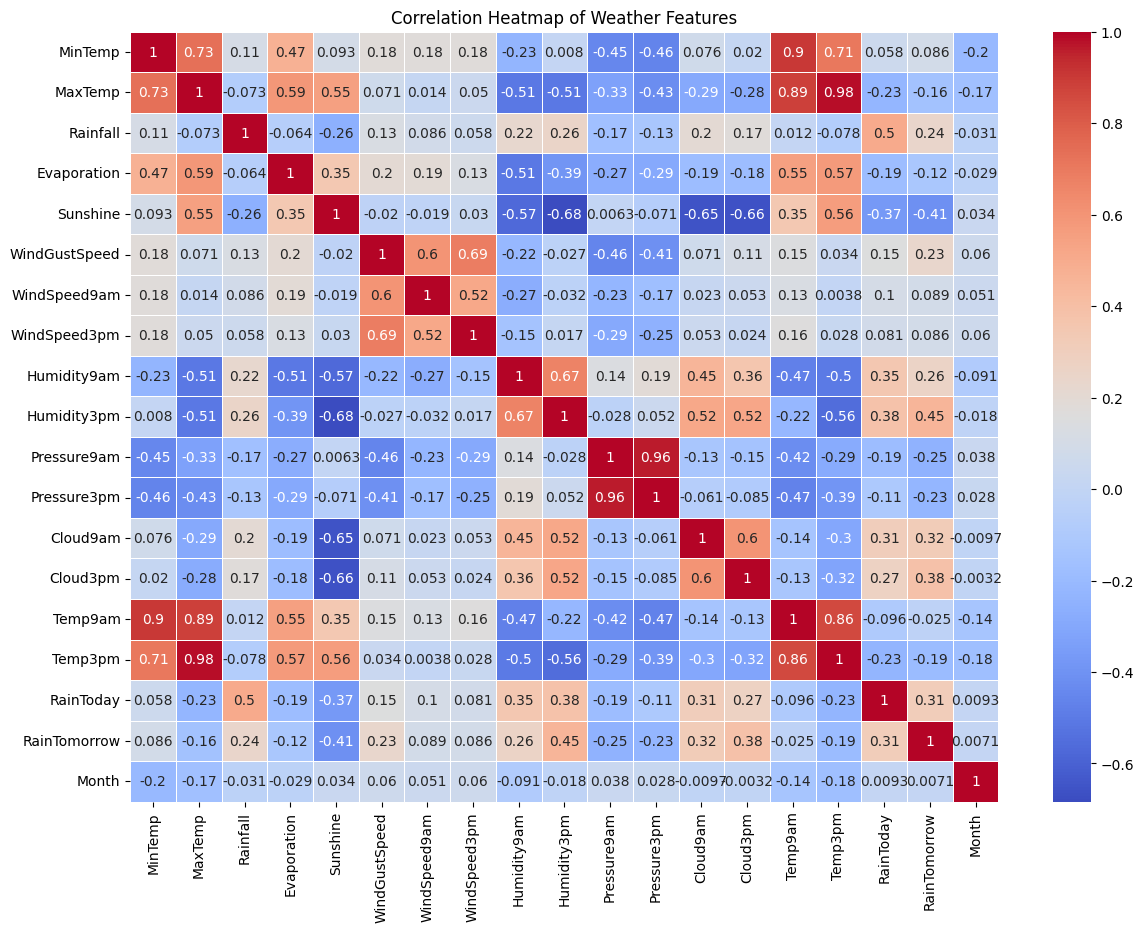

,Sunshine
Sunshine,1.000000
Temp3pm,0.560733
MaxTemp,0.552506
Temp9am,0.347940
Evaporation,0.345421
MinTemp,0.093446
Month,0.034353
WindSpeed3pm,0.029539
Pressure9am,0.006277
WindSpeed9am,-0.018572


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numeric columns for correlation analysis
numeric_cols = df.select_dtypes(include=['float64', 'int64', 'bool']).columns
corr_matrix = df[numeric_cols].corr()

# Focus specifically on correlations with 'Sunshine'
sunshine_corr = corr_matrix['Sunshine'].sort_values(ascending=False).to_frame()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Weather Features')
plt.show()

display(sunshine_corr.style.background_gradient(cmap='viridis'))

In [ ]:
# Check for remaining missing values in all columns
missing_values = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Combine into a summary table
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

display(missing_summary[missing_summary['Missing Values'] > 0])

,Missing Values,Percentage (%)
Evaporation,58353,42.035009
Cloud3pm,54729,39.424435
Cloud9am,51372,37.006195
Pressure3pm,12976,9.347356
Pressure9am,12915,9.303414
WindDir9am,9084,6.543726
WindGustDir,8478,6.107189
WindGustSpeed,8450,6.087019
WindDir3pm,3250,2.341161
Humidity3pm,2331,1.679153


In [ ]:
# Define the new target columns and features for imputation
target_cols = ['Evaporation', 'Cloud3pm', 'Cloud9am']
# We include Sunshine (now complete) and other key metrics as predictors
features_for_mice = ['MinTemp', 'MaxTemp', 'Rainfall', 'Humidity9am', 'Temp9am', 'Month', 'Sunshine'] + target_cols

for group_name in ['AI', 'CS', 'TP', 'TS']:
    print(f"Imputing {target_cols} for group: {group_name}...")

    mask = df['weather_trend_group'] == group_name
    df_group = df[mask].copy()

    # Prepare subset for MICE
    data_subset = df_group[features_for_mice].copy()

    # Initialize and fit MICE
    imputer = IterativeImputer(random_state=42, max_iter=10)
    imputed_values = imputer.fit_transform(data_subset)

    # Align indices and update main DataFrame
    df_temp = pd.DataFrame(imputed_values, columns=features_for_mice, index=df_group.index)
    df.loc[mask, target_cols] = df_temp[target_cols]

print("\nImputation complete for Evaporation and Cloud features.")

Imputing ['Evaporation', 'Cloud3pm', 'Cloud9am'] for group: AI...
Imputing ['Evaporation', 'Cloud3pm', 'Cloud9am'] for group: CS...
Imputing ['Evaporation', 'Cloud3pm', 'Cloud9am'] for group: TP...
Imputing ['Evaporation', 'Cloud3pm', 'Cloud9am'] for group: TS...

Imputation complete for Evaporation and Cloud features.


In [ ]:
# Verify remaining missing values for the newly imputed columns
print("Missing values after imputation:")
display(df[target_cols].isnull().sum())

Missing values after imputation:


,0
Evaporation,0
Cloud3pm,0
Cloud9am,0


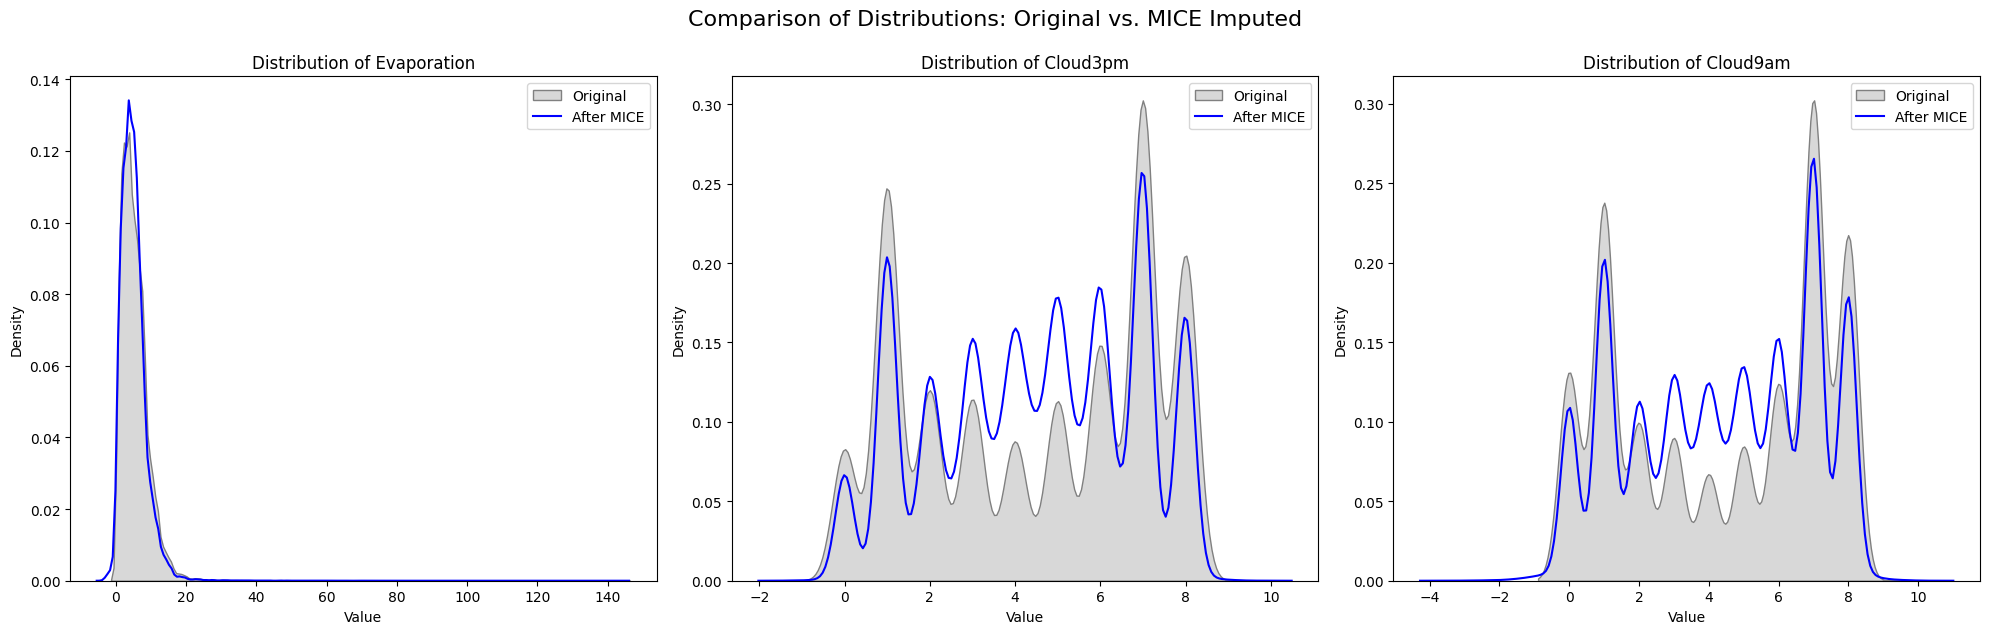

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Features to visualize
features_to_plot = ['Evaporation', 'Cloud3pm', 'Cloud9am']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, col in enumerate(features_to_plot):
    # Plot original distribution (from df_raw, where we have the original data before imputation)
    # We align the indices to ensure we are looking at the same rows if possible
    sns.kdeplot(df_raw.loc[df.index, col].dropna(), ax=axes[i], label='Original', fill=True, color='gray', alpha=0.3)

    # Plot distribution after imputation
    sns.kdeplot(df[col], ax=axes[i], label='After MICE', color='blue')

    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Density')
    axes[i].legend()

plt.tight_layout()
plt.suptitle('Comparison of Distributions: Original vs. MICE Imputed', y=1.05, fontsize=16)
plt.show()

In [ ]:
# Define target pressure columns and predictors
pressure_cols = ['Pressure9am', 'Pressure3pm']
# Use previously imputed and core features as predictors
predictors = ['MinTemp', 'MaxTemp', 'Rainfall', 'Humidity9am', 'Temp9am', 'Month', 'Sunshine', 'Evaporation', 'Cloud3pm', 'Cloud9am']
features_for_pressure = predictors + pressure_cols

for group_name in ['AI', 'CS', 'TP', 'TS']:
    print(f"Imputing Pressure features for group: {group_name}...")

    mask = df['weather_trend_group'] == group_name
    df_group = df[mask].copy()

    # Prepare subset
    data_subset = df_group[features_for_pressure].copy()

    # Initialize and fit MICE
    imputer = IterativeImputer(random_state=42, max_iter=10)
    imputed_values = imputer.fit_transform(data_subset)

    # Map back to main DataFrame
    df_temp = pd.DataFrame(imputed_values, columns=features_for_pressure, index=df_group.index)
    df.loc[mask, pressure_cols] = df_temp[pressure_cols]

print("\nImputation complete for Pressure9am and Pressure3pm.")
display(df[pressure_cols].isnull().sum())

Imputing Pressure features for group: AI...


/usr/local/lib/python3.12/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


Imputing Pressure features for group: CS...
Imputing Pressure features for group: TP...
Imputing Pressure features for group: TS...

Imputation complete for Pressure9am and Pressure3pm.


,0
Pressure9am,0
Pressure3pm,0


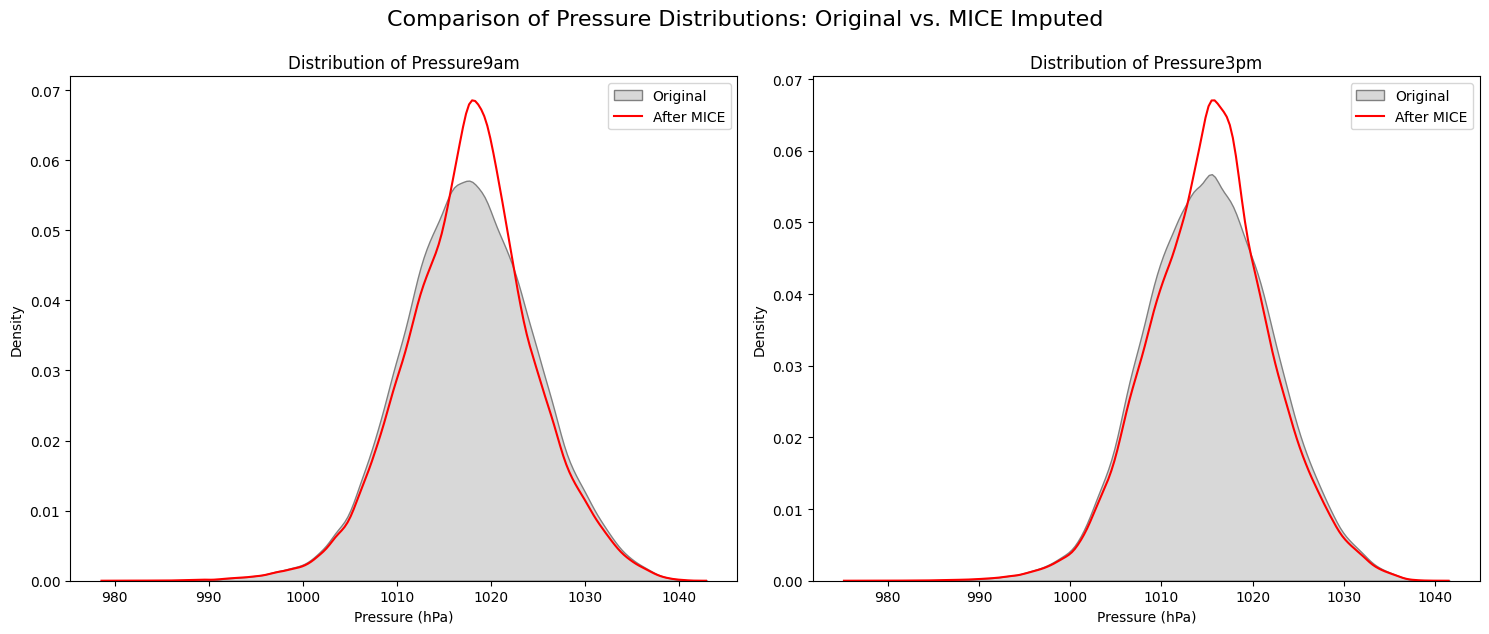

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Features to visualize
pressure_features = ['Pressure9am', 'Pressure3pm']

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for i, col in enumerate(pressure_features):
    # Plot original distribution (dropping NaNs from the raw dataframe)
    sns.kdeplot(df_raw.loc[df.index, col].dropna(), ax=axes[i], label='Original', fill=True, color='gray', alpha=0.3)

    # Plot distribution after imputation
    sns.kdeplot(df[col], ax=axes[i], label='After MICE', color='red')

    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel('Pressure (hPa)')
    axes[i].set_ylabel('Density')
    axes[i].legend()

plt.tight_layout()
plt.suptitle('Comparison of Pressure Distributions: Original vs. MICE Imputed', y=1.05, fontsize=16)
plt.show()

In [ ]:
from sklearn.impute import KNNImputer, IterativeImputer, SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 1. Setup Evaluation for Numeric Wind Speeds
target_eval = "WindGustSpeed"
wind_speed_cols = ["WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]
knn_features = ["MinTemp", "MaxTemp", "Rainfall", "Humidity9am", "Temp9am", "Sunshine", "Pressure9am", "Pressure3pm", "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]

# Filter ground truth data
df_eval_wind = df_raw.loc[df.index, knn_features].dropna()
train_idx, test_idx = train_test_split(df_eval_wind.index, test_size=0.2, random_state=42)

y_true = df_eval_wind.loc[test_idx, target_eval]

# --- MICE Evaluation ---
df_mice_masked = df_eval_wind.copy()
df_mice_masked.loc[test_idx, target_eval] = np.nan
mice_eval = IterativeImputer(random_state=42, max_iter=10)
mice_imputed = mice_eval.fit_transform(df_mice_masked)
y_pred_mice = pd.DataFrame(mice_imputed, columns=knn_features, index=df_eval_wind.index).loc[test_idx, target_eval]

# --- KNN Evaluation ---
df_knn_masked = df_eval_wind.copy()
df_knn_masked.loc[test_idx, target_eval] = np.nan
knn_eval = KNNImputer(n_neighbors=5)
knn_imputed = knn_eval.fit_transform(df_knn_masked)
y_pred_knn = pd.DataFrame(knn_imputed, columns=knn_features, index=df_eval_wind.index).loc[test_idx, target_eval]

# Compare Results
results = {
    "Metric": ["RMSE", "R2 Score"],
    "MICE": [np.sqrt(mean_squared_error(y_true, y_pred_mice)), r2_score(y_true, y_pred_mice)],
    "KNN": [np.sqrt(mean_squared_error(y_true, y_pred_knn)), r2_score(y_true, y_pred_knn)]
}
display(pd.DataFrame(results))

# 2. Final Imputation (Using KNN as per standard practice for these wind features)
wind_dir_cols = ["WindGustDir", "WindDir9am", "WindDir3pm"]
for group_name in ["AI", "CS", "TP", "TS"]:
    mask = df["weather_trend_group"] == group_name
    df_group = df[mask].copy()

    # Numeric speeds (KNN)
    knn_imputer = KNNImputer(n_neighbors=5)
    df.loc[mask, wind_speed_cols] = pd.DataFrame(knn_imputer.fit_transform(df_group[knn_features]), columns=knn_features, index=df_group.index)[wind_speed_cols]

    # Categorical directions (Mode)
    mode_imputer = SimpleImputer(strategy="most_frequent")
    df.loc[mask, wind_dir_cols] = mode_imputer.fit_transform(df_group[wind_dir_cols])

print("\nFinal Check for Missing values in wind features:")
print(df[wind_speed_cols + wind_dir_cols].isnull().sum())

,Metric,MICE,KNN
0,RMSE,7.933865,8.052343
1,R2 Score,0.646880,0.636255



Final Check for Missing values in wind features:
WindGustSpeed    0
WindSpeed9am     0
WindSpeed3pm     0
WindGustDir      0
WindDir9am       0
WindDir3pm       0
dtype: int64


In [ ]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# Define target columns and predictors
residual_cols = ['Humidity3pm', 'Temp3pm']
predictors = ['MinTemp', 'MaxTemp', 'Rainfall', 'Humidity9am', 'Temp9am', 'Month', 'Sunshine', 'Evaporation', 'Cloud3pm', 'Cloud9am', 'Pressure9am', 'Pressure3pm']
features_for_mice = predictors + residual_cols

for group_name in ['AI', 'CS', 'TP', 'TS']:
    print(f"Imputing {residual_cols} for group: {group_name}...")
    mask = df['weather_trend_group'] == group_name
    df_group = df[mask].copy()

    # Prepare subset and impute
    data_subset = df_group[features_for_mice].copy()
    imputer = IterativeImputer(random_state=42, max_iter=10)
    imputed_values = imputer.fit_transform(data_subset)

    # Update main DataFrame
    df_temp = pd.DataFrame(imputed_values, columns=features_for_mice, index=df_group.index)
    df.loc[mask, residual_cols] = df_temp[residual_cols]

print("\nFinal check for any missing values in the entire DataFrame:")
display(df.isnull().sum())

Imputing ['Humidity3pm', 'Temp3pm'] for group: AI...
Imputing ['Humidity3pm', 'Temp3pm'] for group: CS...
Imputing ['Humidity3pm', 'Temp3pm'] for group: TP...
Imputing ['Humidity3pm', 'Temp3pm'] for group: TS...

Final check for any missing values in the entire DataFrame:


,0
Date,0
Location,0
MinTemp,0
MaxTemp,0
Rainfall,0
Evaporation,0
Sunshine,0
WindGustDir,0
WindGustSpeed,0
WindDir9am,0


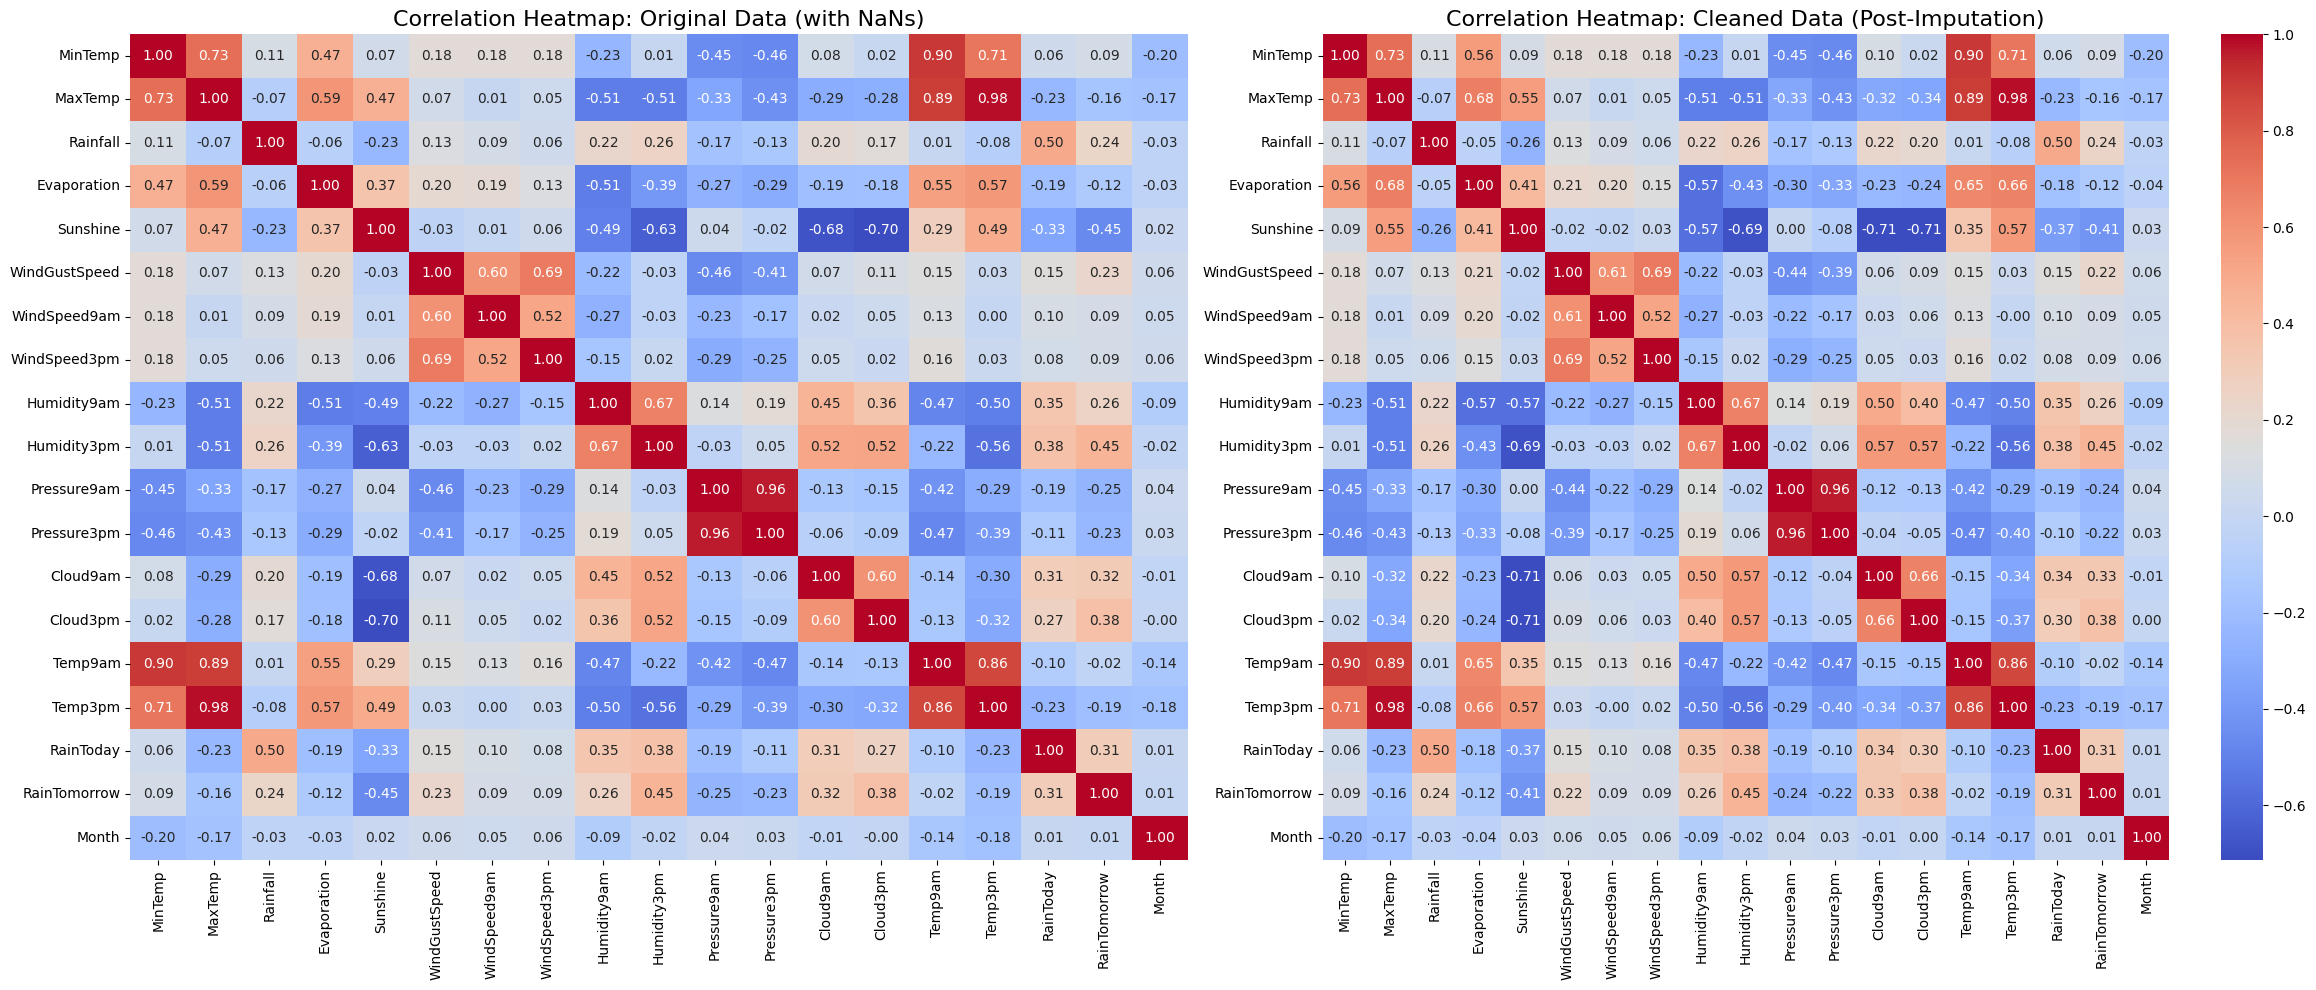

Maximum correlation change after imputation:
Evaporation      0.098712
Temp9am          0.098712
MinTemp          0.091567
MaxTemp          0.088548
Temp3pm          0.084854
Sunshine         0.083467
Humidity9am      0.077811
Pressure3pm      0.062161
Cloud9am         0.059293
Cloud3pm         0.059293
Humidity3pm      0.056475
RainToday        0.041668
Pressure9am      0.039283
RainTomorrow     0.039083
Rainfall         0.034574
WindSpeed9am     0.026347
WindSpeed3pm     0.025668
WindGustSpeed    0.018544
Month            0.015040
dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numeric columns present in both dataframes
numeric_cols = df.select_dtypes(include=['float64', 'int64', 'bool']).columns

fig, axes = plt.subplots(1, 2, figsize=(24, 10))

# Correlation for Raw Data (using original indices from df to match rows)
corr_raw = df_raw.loc[df.index, numeric_cols].corr()
sns.heatmap(corr_raw, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[0], cbar=False)
axes[0].set_title('Correlation Heatmap: Original Data (with NaNs)', fontsize=16)

# Correlation for Cleaned Data (after Imputation)
corr_cleaned = df[numeric_cols].corr()
sns.heatmap(corr_cleaned, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1])
axes[1].set_title('Correlation Heatmap: Cleaned Data (Post-Imputation)', fontsize=16)

plt.tight_layout()
plt.show()

# Calculate the absolute difference in correlations to highlight changes
corr_diff = (corr_cleaned - corr_raw).abs()
print("Maximum correlation change after imputation:")
print(corr_diff.max().sort_values(ascending=False))

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# Define target variable (y) and features (X)
y = df['RainTomorrow'].astype(int) # Convert boolean target to integer (0 or 1)
X = df.drop(columns=['RainTomorrow', 'weather_trend_group'])

# Identify categorical and numerical columns for preprocessing
categorical_features = X.select_dtypes(include=['object', 'bool']).columns
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns

# Create a preprocessor to handle categorical features with OneHotEncoder
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', 'passthrough', numerical_features)
    ])

# Split data into training and a temporary set (for evaluation and test)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Split the temporary set into evaluation and test sets
X_eval, X_test, y_eval, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_eval shape: {X_eval.shape}, y_eval shape: {y_eval.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

# Create a Decision Tree Classifier pipeline
# The pipeline will first preprocess the data and then apply the Decision Tree Classifier
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42, max_depth=5)) # Added max_depth to prevent overfitting
])

# Train the model
model.fit(X_train, y_train)

# Evaluate the model on the evaluation set
y_pred_eval = model.predict(X_eval)
accuracy_eval = accuracy_score(y_eval, y_pred_eval)
report_eval = classification_report(y_eval, y_pred_eval)

print(f"\nDecision Tree Classifier Evaluation Results (on evaluation set):")
print(f"Accuracy: {accuracy_eval:.4f}")
print("Classification Report:")
print(report_eval)

# Optional: Evaluate on the test set (after final model selection/tuning)
y_pred_test = model.predict(X_test)
accuracy_test = accuracy_score(y_test, y_pred_test)
report_test = classification_report(y_test, y_pred_test)

print(f"\nDecision Tree Classifier Test Results (on test set):")
print(f"Accuracy: {accuracy_test:.4f}")
print("Classification Report:")
print(report_test)

X_train shape: (97174, 23), y_train shape: (97174,)
X_eval shape: (20823, 23), y_eval shape: (20823,)
X_test shape: (20823, 23), y_test shape: (20823,)

Decision Tree Classifier Evaluation Results (on evaluation set):
Accuracy: 0.8429
Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.95      0.90     16223
           1       0.74      0.45      0.56      4600

    accuracy                           0.84     20823
   macro avg       0.80      0.70      0.73     20823
weighted avg       0.83      0.84      0.83     20823


Decision Tree Classifier Test Results (on test set):
Accuracy: 0.8439
Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.95      0.90     16223
           1       0.73      0.46      0.57      4600

    accuracy                           0.84     20823
   macro avg       0.80      0.71      0.74     20823
weighted avg       0.83      0.84      0.83     2

In [ ]:
from sklearn.metrics import roc_auc_score, f1_score, recall_score

# Evaluate the model on the training set
y_pred_train = model.predict(X_train)
y_proba_train = model.predict_proba(X_train)[:, 1] # Probability of 'True' class
accuracy_train = accuracy_score(y_train, y_pred_train)
report_train = classification_report(y_train, y_pred_train, output_dict=True)
auc_roc_train = roc_auc_score(y_train, y_proba_train)
f1_train_yes = report_train['1']['f1-score']
recall_train_yes = report_train['1']['recall']

print(f"Decision Tree Classifier Training Results:")
print(f"Accuracy: {accuracy_train:.4f}")
print(f"AUC-ROC: {auc_roc_train:.4f}")
print(f"F1 Score (Yes): {f1_train_yes:.4f}")
print(f"Recall (Yes): {recall_train_yes:.4f}")

# Evaluate the model on the evaluation set
y_pred_eval = model.predict(X_eval)
y_proba_eval = model.predict_proba(X_eval)[:, 1] # Probability of 'True' class
accuracy_eval = accuracy_score(y_eval, y_pred_eval)
report_eval = classification_report(y_eval, y_pred_eval, output_dict=True)
auc_roc_eval = roc_auc_score(y_eval, y_proba_eval)
f1_eval_yes = report_eval['1']['f1-score']
recall_eval_yes = report_eval['1']['recall']

print(f"\nDecision Tree Classifier Evaluation Results:")
print(f"Accuracy: {accuracy_eval:.4f}")
print(f"AUC-ROC: {auc_roc_eval:.4f}")
print(f"F1 Score (Yes): {f1_eval_yes:.4f}")
print(f"Recall (Yes): {recall_eval_yes:.4f}")

# Evaluate on the test set
y_pred_test = model.predict(X_test)
y_proba_test = model.predict_proba(X_test)[:, 1] # Probability of 'True' class
accuracy_test = accuracy_score(y_test, y_pred_test)
report_test = classification_report(y_test, y_pred_test, output_dict=True)
auc_roc_test = roc_auc_score(y_test, y_proba_test)
f1_test_yes = report_test['1']['f1-score']
recall_test_yes = report_test['1']['recall']

print(f"\nDecision Tree Classifier Test Results:")
print(f"Accuracy: {accuracy_test:.4f}")
print(f"AUC-ROC: {auc_roc_test:.4f}")
print(f"F1 Score (Yes): {f1_test_yes:.4f}")
print(f"Recall (Yes): {recall_test_yes:.4f}")

Decision Tree Classifier Training Results:
Accuracy: 0.8442
AUC-ROC: 0.8404
F1 Score (Yes): 0.5638
Recall (Yes): 0.4557

Decision Tree Classifier Evaluation Results:
Accuracy: 0.8429
AUC-ROC: 0.8391
F1 Score (Yes): 0.5579
Recall (Yes): 0.4487

Decision Tree Classifier Test Results:
Accuracy: 0.8439
AUC-ROC: 0.8452
F1 Score (Yes): 0.5668
Recall (Yes): 0.4624


### Optimisation des hyperparamètres avec GridSearchCV

Nous allons maintenant utiliser `GridSearchCV` pour trouver les meilleurs hyperparamètres pour notre `DecisionTreeClassifier`. Cette méthode explore systématiquement toutes les combinaisons de paramètres spécifiées dans une grille et utilise la validation croisée pour évaluer la performance de chaque combinaison.

In [120]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid to search
param_grid = {
    'classifier__max_depth': [6, 7,8,9],  # None means unlimited depth
    'classifier__min_samples_split': [9,10,11],
    'classifier__min_samples_leaf': [3,4,5,6]
}

# Create a GridSearchCV object
# We pass the pipeline ('model') that includes preprocessing and the classifier
grid_search = GridSearchCV(
    estimator=model, # Our existing pipeline
    param_grid=param_grid,
    cv=5, # 5-fold cross-validation
    scoring='roc_auc', # Optimize for AUC-ROC score
    n_jobs=-1, # Use all available CPU cores
    verbose=1 # Display progress
)

print("Starting GridSearchCV...")
# Fit GridSearchCV to the training data
grid_search.fit(X_train, y_train)
print("GridSearchCV complete.")

# Get the best parameters and best score
best_params = grid_search.best_params_
best_score = grid_search.best_score_

print(f"\nMeilleurs hyperparamètres trouvés: {best_params}")
print(f"Meilleur score AUC-ROC en cross-validation: {best_score:.4f}")

# Get the best model from the grid search
best_model = grid_search.best_estimator_

# Evaluate the best model on the test set
y_pred_best = best_model.predict(X_test)
y_proba_best = best_model.predict_proba(X_test)[:, 1]

accuracy_best = accuracy_score(y_test, y_pred_best)
auc_roc_best = roc_auc_score(y_test, y_proba_best)
report_best = classification_report(y_test, y_pred_best, output_dict=True)
f1_best_yes = report_best['1']['f1-score']
recall_best_yes = report_best['1']['recall']

print(f"\nPerformance du meilleur modèle sur l'ensemble de test:")
print(f"Accuracy: {accuracy_best:.4f}")
print(f"AUC-ROC: {auc_roc_best:.4f}")
print(f"F1 Score (Yes): {f1_best_yes:.4f}")
print(f"Recall (Yes): {recall_best_yes:.4f}")

Starting GridSearchCV...
Fitting 5 folds for each of 48 candidates, totalling 240 fits
GridSearchCV complete.

Meilleurs hyperparamètres trouvés: {'classifier__max_depth': 8, 'classifier__min_samples_leaf': 6, 'classifier__min_samples_split': 9}
Meilleur score AUC-ROC en cross-validation: 0.8473

Performance du meilleur modèle sur l'ensemble de test:
Accuracy: 0.8459
AUC-ROC: 0.8575
F1 Score (Yes): 0.5932
Recall (Yes): 0.5085


### Decision Tree Visualization

Let's visualize the trained Decision Tree. Due to the potential complexity of the tree, only a portion might be clearly visible, but it will illustrate the decision-making process.

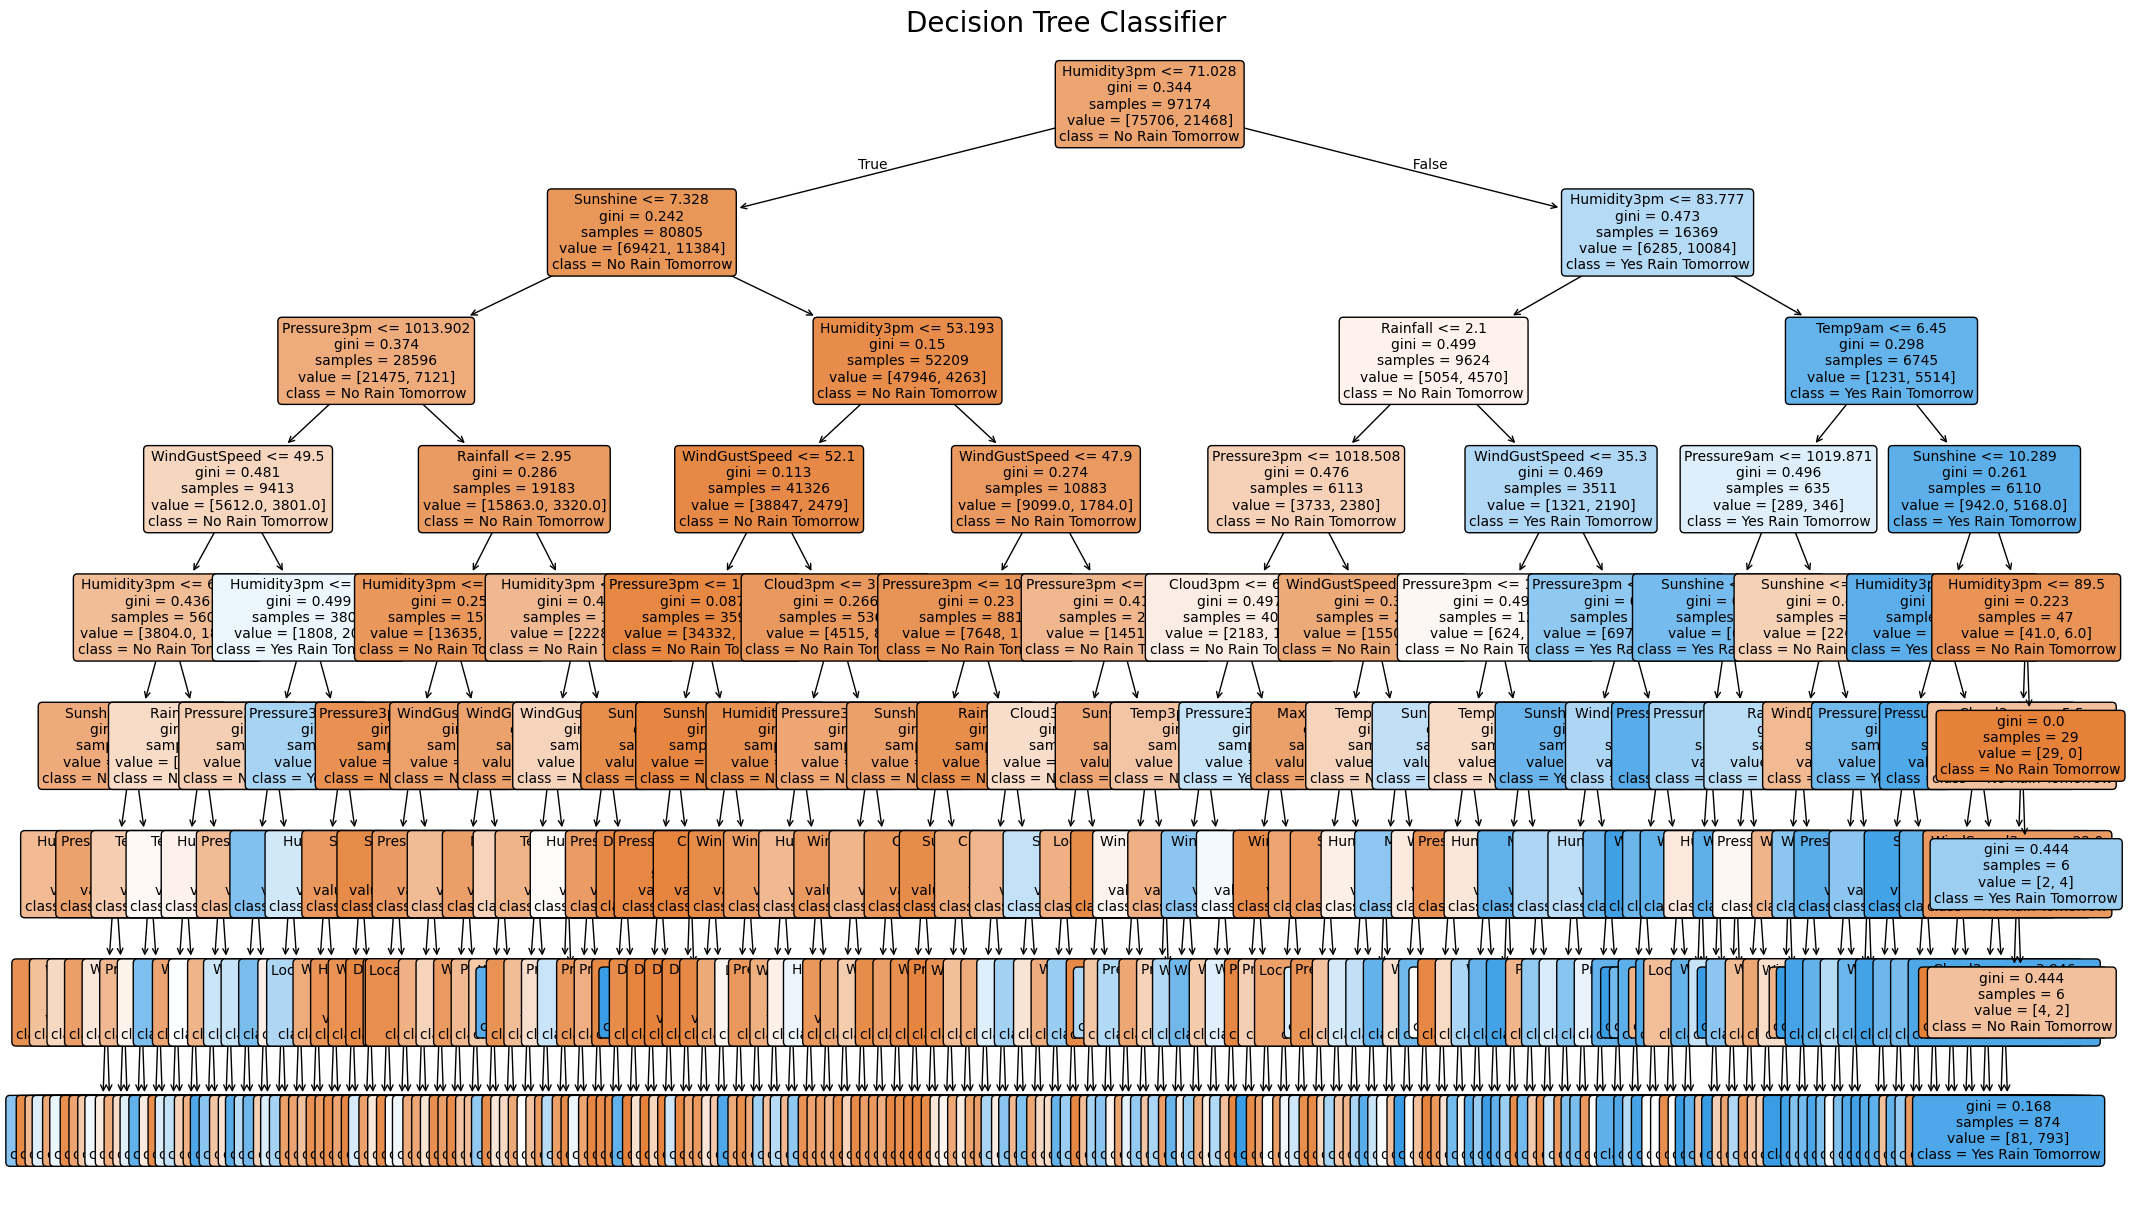

In [121]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Extract the trained Decision Tree Classifier from the pipeline
decision_tree = best_model.named_steps['classifier']

one_hot_features = best_model.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(categorical_features)
all_feature_names = list(one_hot_features) + list(numerical_features)

plt.figure(figsize=(25, 15))
plot_tree(decision_tree,
          feature_names=all_feature_names,
          class_names=['No Rain Tomorrow', 'Yes Rain Tomorrow'],
          filled=True,
          rounded=True,
          fontsize=10,
          # max_depth=3 # Limiting depth for better readability
         )
plt.title('Decision Tree Classifier', fontsize=20)
plt.show()

In [122]:
# Install dtreeviz for interactive visualization
!pip install dtreeviz

In [ ]:
import dtreeviz

# Transform X_train using the preprocessor to get the numerical data for dtreeviz
X_train_transformed = model.named_steps['preprocessor'].transform(X_train)

# Convert sparse matrix to dense array for dtreeviz compatibility
X_train_transformed = X_train_transformed.toarray()

# Get the feature names after one-hot encoding for dtreeviz
one_hot_features = best_model.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(categorical_features)
feature_names_dtreeviz = list(one_hot_features) + list(numerical_features)

# Extract the trained Decision Tree Classifier
decision_tree_classifier = best_model.named_steps['classifier']

# Create the dtreeviz visualization object
viz = dtreeviz.model(
    decision_tree_classifier,
    X_train=X_train_transformed,
    y_train=y_train,
    feature_names=feature_names_dtreeviz,
    target_name='RainTomorrow',
    class_names=['No Rain Tomorrow', 'Yes Rain Tomorrow'],
    # title="Interactive Decision Tree Visualization"
)

# Display the visualization
viz.view()

La location ne rentre jamais dans le decision tree